In [37]:
print("Installing dependency")
!pip install -q --upgrade --force-reinstall transformers==4.40.0
!pip install -q kaggle pandas numpy nltk langdetect textblob
!pip install -q torch keybert
!pip install -q gradio matplotlib seaborn wordcloud
!pip install -q deep-translator

Installing dependency
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
httpx 0.13.3 requires idna==2.*, but you have idna 3.18 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.4.0 which is incompatible.
litellm 1.82.4 requires httpx>=0.23.0, but you have httpx 0.13.3 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
a2a-sdk 0.3.26 requires httpx>=0.28.1, but you have httpx 0.13.3 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, bu

In [38]:
import os
#get Kaggle credentials
os.environ['KAGGLE_CONFIG_DIR']=os.getcwd()

print("Download datasets from Kaggle")
!kaggle datasets download -d yelp-dataset/yelp-dataset --unzip #download yelp dataset that contain English reviews
!kaggle datasets download -d mksaad/arabic-sentiment-twitter-corpus --unzip #download Twitter dataset that contain Arabic comments
print("data download complete")

Download datasets from Kaggle
Dataset URL: https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset
License(s): other
100%|██████████████████████████████████████| 4.07G/4.07G [00:18<00:00, 232MB/s]

Dataset URL: https://www.kaggle.com/datasets/mksaad/arabic-sentiment-twitter-corpus
License(s): Community Data License Agreement - Sharing - Version 1.0
100%|██████████████████████████████████████| 16.9M/16.9M [00:00<00:00, 184MB/s]

data download complete


In [39]:
import pandas as pd
import re
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

print("Loading data files i")
yelp_file = 'yelp_academic_dataset_review.json'
ar_pos_file = 'train_Arabic_tweets_positive_20190413.tsv'
ar_neg_file = 'train_Arabic_tweets_negative_20190413.tsv'

#load English data 
if os.path.exists(yelp_file):
    print(f"   Ingesting English reviews from: {yelp_file}")
    df_en_chunk = pd.read_json(yelp_file, lines=True, chunksize=5000)
    df_en = next(df_en_chunk)[['text', 'stars']]
    df_en.rename(columns={'text': 'review_text'}, inplace=True)
    df_en['language'] = 'en'
else:
    raise FileNotFoundError(f"Missing mandatory data path: {yelp_file}")

#load Arabic data
df_ar_list = []
def load_arabic_tsv(filename):
    if os.path.exists(filename):
        print(f"   Ingesting Arabic records from: {filename}")
        df = pd.read_csv(filename, sep='\t', on_bad_lines='skip', nrows=2500, header=None)
        text_col = max(df.columns, key=lambda c: df[c].dropna().astype(str).str.len().mean())
        return df[[text_col]].rename(columns={text_col: 'review_text'})
    return None

#load Arabic neg and pos tweets and store them
df_pos = load_arabic_tsv(ar_pos_file)
df_neg = load_arabic_tsv(ar_neg_file)
if df_pos is not None: df_ar_list.append(df_pos)
if df_neg is not None: df_ar_list.append(df_neg)

#merge arabic data
if df_ar_list:
    df_ar = pd.concat(df_ar_list, ignore_index=True)
    df_ar['language'] = 'ar'
else:
    raise FileNotFoundError("Arabic source data documents could not be mapped correctly.")

#combine arabic and english data
df = pd.concat([df_en, df_ar], ignore_index=True)

def clean_text(text):
    if not isinstance(text, str): return ""
    if any('\u0600' <= c <= '\u06FF' for c in text):
        pass
    else:
        text = text.lower()
    text = re.sub(r'[^\w\s\u0600-\u06FF]', '', text)
    return text
#aplly cleaning anf remove empty rows
df['cleaned_text'] = df['review_text'].apply(clean_text)
df = df[df['cleaned_text'].str.strip().astype(bool)].reset_index(drop=True)
print(f"DataFrame compiled successfully. working records: {len(df)}")

Loading data files i
   Ingesting English reviews from: yelp_academic_dataset_review.json
   Ingesting Arabic records from: train_Arabic_tweets_positive_20190413.tsv
   Ingesting Arabic records from: train_Arabic_tweets_negative_20190413.tsv
DataFrame compiled successfully. working records: 10000


In [40]:
from transformers import pipeline
import torch

print("Assessing hardware context")
device = 0 if torch.cuda.is_available() else -1
print("GPU active" if device == 0 else "Running on CPU")

#load pre-trained DistilBERT sentiment model
en_sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True, max_length=512, device=device
)
##load CAMeL-BERT Arabic sentiment model 
ar_sentiment_model = pipeline(
    "text-classification",
    model="CAMeL-Lab/bert-base-arabic-camelbert-mix-sentiment",
    truncation=True, max_length=512, device=device
)
#normalize labels to one format
def normalize_label(label: str) -> str:
    label = label.lower().strip()
    positive_signals = {'positive', 'pos', 'label_1', '1', '5 stars', '4 stars'}
    negative_signals = {'negative', 'neg', 'label_0', '0', '1 star', '2 stars'}
    if label in positive_signals:
        return 'Positive'
    if label in negative_signals:
        return 'Negative'
    return 'Neutral'
#function to predict sentiment for a single dataset row
def get_sentiment(row):
    text = row['cleaned_text'][:200]
    try:
        if row['language'] == 'ar':
            res = ar_sentiment_model(text)[0]
        else:
            res = en_sentiment_model(text)[0]
        return normalize_label(res['label'])
    except Exception:
        return 'Neutral'
#apply sentiment prediction to every row in the dataset
print("Classifying textual corpus records...")
df['sentiment'] = df.apply(get_sentiment, axis=1)
print("Classification complete.")

Assessing hardware context
GPU active


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Classifying textual corpus records...
Classification complete.


In [41]:
print("Analyzing negative AND positive text trends...")

# Negative matrix 
def generate_complaint_matrix(dataframe):
    neg_df = dataframe[dataframe['sentiment'] == 'Negative'].copy()
    #define complaint categories and keywords and add them 
    themes = {
        'Delivery/Shipping': ['delivery', 'shipped', 'late', 'package', 'driver', 'time', 'تاخير', 'توصيل', 'شحن'],
        'Customer Service':  ['service', 'staff', 'manager', 'rude', 'attitude', 'support', 'خدمة', 'موظف', 'تعامل'],
        'Product Quality':   ['quality', 'broken', 'bad', 'taste', 'cold', 'item', 'wrong', 'جودة', 'سيء', 'خربان'],
        'Pricing/Billing':   ['price', 'expensive', 'charge', 'money', 'refund', 'cost', 'سعر', 'غالي', 'فلوس']
    }

    complaint_counts = {k: 0 for k in themes}
    complaint_counts['Other Issues'] = 0
    #loop through every negative review
    for text in neg_df['cleaned_text'].astype(str):
        matched = False
        for category, keywords in themes.items():
            if any(kw in text for kw in keywords):
                complaint_counts[category] += 1
                matched = True
                break
        if not matched:
            complaint_counts['Other Issues'] += 1
    #sort categories from highest frequency to lowest
    df_matrix = pd.DataFrame(list(complaint_counts.items()), columns=['Complaint Category', 'Frequency'])
    return df_matrix.sort_values(by='Frequency', ascending=False).reset_index(drop=True)

# Praise matrix
def generate_praise_matrix(dataframe):
    pos_df = dataframe[dataframe['sentiment'] == 'Positive'].copy()
    ##define praise categories and keywords and add them 
    praise_themes = {
        'Food Quality':      ['delicious', 'tasty', 'fresh', 'amazing', 'great food', 'loved', 'flavor', 'لذيذ', 'طازج', 'رائع'],
        'Fast Service':      ['fast', 'quick', 'prompt', 'efficient', 'on time', 'سريع', 'وقت'],
        'Friendly Staff':    ['friendly', 'kind', 'helpful', 'polite', 'nice', 'welcoming', 'ودود', 'محترم', 'لطيف'],
        'Value for Money':   ['worth', 'affordable', 'cheap', 'reasonable', 'great price', 'value', 'مناسب', 'رخيص', 'يستاهل'],
        'Ambiance/Location': ['atmosphere', 'clean', 'cozy', 'beautiful', 'location', 'comfortable', 'نظيف', 'جميل', 'مريح']
    }

    praise_counts = {k: 0 for k in praise_themes}
    praise_counts['General Praise'] = 0
    #loop through every negative review
    for text in pos_df['cleaned_text'].astype(str):
        matched = False
        for category, keywords in praise_themes.items():
            if any(kw in text for kw in keywords):
                praise_counts[category] += 1
                matched = True
                break
        if not matched:
            praise_counts['General Praise'] += 1
    #sort categories from highest frequency to lowest
    df_matrix = pd.DataFrame(list(praise_counts.items()), columns=['Praise Category', 'Frequency'])
    return df_matrix.sort_values(by='Frequency', ascending=False).reset_index(drop=True)

df_complaints_summary = generate_complaint_matrix(df)
df_praise_summary = generate_praise_matrix(df)
print("Complaint and praise categories constructed.")

Analyzing negative AND positive text trends...
Complaint and praise categories constructed.


In [42]:
print("Instantiating BART Summarizer")
from transformers import BartTokenizer, BartForConditionalGeneration

#use facebook/bart-large-cnn which is optimized for summarization
bart_model_name= "facebook/bart-large-cnn"
bart_tokenizer= BartTokenizer.from_pretrained(bart_model_name)
bart_model = BartForConditionalGeneration.from_pretrained(bart_model_name)

#put model into evaluation mode
if device == 0:
    bart_model = bart_model.to("cuda")
bart_model.eval()

def bart_summarize(text_block):
    """Run BART summarization on any text block."""
    if len(text_block.strip()) < 50:
        return "Not enough text to summarize."
    try:
        inputs = bart_tokenizer(
            text_block, return_tensors="pt",
            max_length=1024, truncation=True
        )
        if device == 0:
            inputs = {k: v.to("cuda") for k, v in inputs.items()}
        summary_ids = bart_model.generate(
            inputs["input_ids"],
            num_beams=4, max_length=130, min_length=30, early_stopping=True
        ) #define beams and summary lengths
        return bart_tokenizer.decode(summary_ids[0], skip_special_tokens=True)
    except Exception as e:
        return f"Summarization failed: {str(e)}"

#generate both summaries 
negative_corpus = " ".join(
    df[df['sentiment'] == 'Negative']['review_text'].head(15).tolist()
)[:1024]
positive_corpus = " ".join(
    df[df['sentiment'] == 'Positive']['review_text'].head(15).tolist()
)[:1024]
#print first 80 characters of summary
print("Generating negative feedback summary...")
system_negative_summary = bart_summarize(negative_corpus)
print(f"Negative Summary: '{system_negative_summary[:80]}...'")

print("Generating positive feedback summary...")
system_positive_summary = bart_summarize(positive_corpus)
print(f"Positive Summary: '{system_positive_summary[:80]}...'")

Instantiating BART Summarizer


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

Generating negative feedback summary...
Negative Summary: 'The food is good, but it takes a very long time to come out. The waitstaff is ve...'
Generating positive feedback summary...
Positive Summary: 'The online scheduling system makes it easy to plan ahead. Russell always wears a...'


In [55]:
print("Loading TinyLlama-1.1B-Chat model")
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForCausalLM
from deep_translator import GoogleTranslator

tinyllama_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
tinyllama_tokenizer = AutoTokenizer.from_pretrained(tinyllama_name)
tinyllama_model = AutoModelForCausalLM.from_pretrained(
    tinyllama_name,
    torch_dtype=torch.float16 if device == 0 else torch.float32,
    device_map="auto" if device == 0 else None
)
#put model into evaluation mode
if device != 0:
    tinyllama_model = tinyllama_model.to("cpu")
tinyllama_model.eval()
print("TinyLlama ready.")

#determine what type of question the user is asking
def detect_intent(query_lower):
    neg_keywords = ["negative", "bad", "complaint", "issue", "problem",
                    "delivery", "worst", "hate", "slow", "rude", "مشكلة", "سيء", "شكوى"]
    pos_keywords = ["positive", "good", "great", "love", "best", "praise",
                    "happy", "excellent", "enjoy", "recommend", "ممتاز", "جميل", "احسن"]
    cmp_keywords = ["compare", "vs", "versus", "difference", "both", "overall", "trend"]
    stat_keywords = ["how many", "count", "percent", "percentage", "total",
                     "ratio", "breakdown", "distribution", "stats", "statistics"]

    #check question types
    if any(k in query_lower for k in stat_keywords):  return 'stats'
    if any(k in query_lower for k in cmp_keywords):   return 'comparison'
    if any(k in query_lower for k in neg_keywords):   return 'negative'
    if any(k in query_lower for k in pos_keywords):   return 'positive'
    return 'general'

def build_context(query_lower):
    total= len(df)
    pos_n = len(df[df["sentiment"] == "Positive"])
    neg_n = len(df[df["sentiment"] == "Negative"])
    neu_n = len(df[df["sentiment"] == "Neutral"])
    pos_pct = round(pos_n / total * 100, 1) if total else 0
    neg_pct = round(neg_n / total * 100, 1) if total else 0
    neu_pct = round(neu_n / total * 100, 1) if total else 0
    intent = detect_intent(query_lower)
    #create dataset statistics block
    stats_block = (
        f"DATASET OVERVIEW:\n"
        f"- Total reviews: {total:,}\n"
        f"- Positive: {pos_n:,} ({pos_pct}%)\n"
        f"- Negative: {neg_n:,} ({neg_pct}%)\n"
        f"- Neutral:  {neu_n:,} ({neu_pct}%)\n"
    )

    if intent == 'stats':
        context = stats_block
        context += f"\nCOMPLAINT BREAKDOWN:\n{df_complaints_summary.to_string(index=False)}\n"
        context += f"\nPRAISE BREAKDOWN:\n{df_praise_summary.to_string(index=False)}\n"

    elif intent == 'negative':
        samples = df[df["sentiment"] == "Negative"]["review_text"].head(6).tolist()
        sample_text = "\n".join([f"- {r[:200]}" for r in samples])
        context = (
            stats_block +
            f"\nTOP COMPLAINT CATEGORIES:\n{df_complaints_summary.to_string(index=False)}\n"
            f"\nNEGATIVE FEEDBACK SUMMARY:\n{system_negative_summary}\n"
            f"\nSAMPLE NEGATIVE REVIEWS:\n{sample_text}\n"
        )

    elif intent == 'positive':
        samples= df[df["sentiment"] == "Positive"]["review_text"].head(6).tolist()
        sample_text = "\n".join([f"- {r[:200]}" for r in samples])
        context = (
            stats_block +
            f"\nTOP PRAISE CATEGORIES:\n{df_praise_summary.to_string(index=False)}\n"
            f"\nPOSITIVE FEEDBACK SUMMARY:\n{system_positive_summary}\n"
            f"\nSAMPLE POSITIVE REVIEWS:\n{sample_text}\n"
        )

    elif intent == 'comparison':
        neg_samples = df[df["sentiment"] == "Negative"]["review_text"].head(3).tolist()
        pos_samples = df[df["sentiment"] == "Positive"]["review_text"].head(3).tolist()
        context = (
            stats_block +
            f"\nCOMPLAINT CATEGORIES:\n{df_complaints_summary.to_string(index=False)}\n"
            f"\nPRAISE CATEGORIES:\n{df_praise_summary.to_string(index=False)}\n"
            f"\nNEGATIVE SUMMARY: {system_negative_summary}\n"
            f"\nPOSITIVE SUMMARY: {system_positive_summary}\n"
            f"\nSAMPLE NEGATIVE:\n" + "\n".join([f"- {r[:150]}" for r in neg_samples]) + "\n"
            f"\nSAMPLE POSITIVE:\n" + "\n".join([f"- {r[:150]}" for r in pos_samples]) + "\n"
        )
    #general questions
    else:
        samples= df["review_text"].sample(min(6, len(df)), random_state=42).tolist()
        sample_text = "\n".join([f"- {r[:200]}" for r in samples])
        context = (
            stats_block +
            f"\nCOMPLAINT CATEGORIES:\n{df_complaints_summary.to_string(index=False)}\n"
            f"\nPRAISE CATEGORIES:\n{df_praise_summary.to_string(index=False)}\n"
            f"\nOVERALL SUMMARIES:\n"
            f"Negative: {system_negative_summary}\n"
            f"Positive: {system_positive_summary}\n"
            f"\nMIXED SAMPLE REVIEWS:\n{sample_text}\n"
        )
    return context

#main function executed whenever a user asks a question
def chatbot_response(user_query, chat_history=None):
    if chat_history is None:
        chat_history = []

    
    is_arabic = any('\u0600' <= c <= '\u06FF' for c in user_query)
    query_for_model = GoogleTranslator(source='ar', target='en').translate(user_query) if is_arabic else user_query

    #instructions for TinyLlama
    context = build_context(query_for_model.lower())
    system_msg = (
        "You are an expert customer feedback analyst. "
        "You have access to a real dataset of customer reviews. "
        "Answer the user's question directly and specifically using ONLY the numbers, "
        "categories, and review excerpts provided in the context. "
        "Never make up data. If the context does not contain the answer, say so clearly. "
        "Be concise and structured. Use bullet points when listing multiple items."
    )
    #build full prompt
    prompt = (
        f"<|system|>\n{system_msg}\n"
        f"<|user|>\n"
        f"Dataset context:\n{context}\n\n"
        f"User question: {query_for_model}\n"
        f"<|assistant|>\n"
    )

    response_text = ""  
    try:
        inputs = tinyllama_tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=2048
        )
        if device == 0:
            inputs = {k: v.to("cuda") for k, v in inputs.items()}

        #generate chatbot response
        with torch.no_grad():
            output_ids = tinyllama_model.generate(
                inputs["input_ids"],
                max_new_tokens=512,       
                temperature=0.7,          
                top_p=0.9,
                repetition_penalty=1.2,
                do_sample=True,
                pad_token_id=tinyllama_tokenizer.eos_token_id,
                eos_token_id=tinyllama_tokenizer.eos_token_id,
            )

        input_length = inputs["input_ids"].shape[1]
        generated_ids = output_ids[0][input_length:]
        response_text = tinyllama_tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

        
        if is_arabic and response_text:
            response_text = GoogleTranslator(source='en', target='ar').translate(response_text)

        if not response_text:
            response_text = "لم أتمكن من توليد رد. حاول بصياغة مختلفة." if is_arabic else "I could not generate a response. Try rephrasing your question."

    except Exception as e:
        response_text = f"خطأ: {str(e)}" if is_arabic else f"Error: {str(e)}"

    chat_history.append((user_query, response_text))
    return "", chat_history #return response to Gradio interface

print("TinyLlama Chatbot ready.")

Loading TinyLlama-1.1B-Chat model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TinyLlama ready.
TinyLlama Chatbot ready.


In [56]:
def generate_dashboard_chart():
    fig, axes = plt.subplots(1, 3, figsize=(20, 6)) # Create a figure containing 1 row and 3 columns of charts

    sentiment_counts = df['sentiment'].value_counts()
    colors = ['#2ecc71', '#e74c3c', '#95a5a6']
    sns.barplot(
        x=sentiment_counts.index,
        y=sentiment_counts.values,
        ax=axes[0],
        palette=colors[:len(sentiment_counts)]
    )
    axes[0].set_title("Overall Sentiment Distribution", fontsize=12, fontweight='bold') # Set chart title
    axes[0].set_ylabel("Review Count")
    for i, v in enumerate(sentiment_counts.values):
        axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')
     # Create bar chart
    sns.barplot(
        data=df_complaints_summary,
        x='Frequency', y='Complaint Category',
        ax=axes[1], palette="Reds_r"
    )
    axes[1].set_title("Top Complaint Categories (Negative)", fontsize=12, fontweight='bold')  # Displays most common complaint categories
    axes[1].set_xlabel("Frequency")

    # Displays most common praise categories
    sns.barplot(
        data=df_praise_summary,
        x='Frequency', y='Praise Category',
        ax=axes[2], palette="Greens_r"
    )
    axes[2].set_title("Top Praise Categories (Positive)", fontsize=12, fontweight='bold')
    axes[2].set_xlabel("Frequency")

    plt.tight_layout() # Prevents overlapping labels and titles
    return fig

/tmp/ipykernel_58/913129992.py:4: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:
/tmp/ipykernel_58/2243628366.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_58/2243628366.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_58/2243628366.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_58/913129992.py:27: UserWarning: You have n

* Running on local URL:  http://127.0.0.1:7866
* Running on public URL: https://9aa9fde2263075b888.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


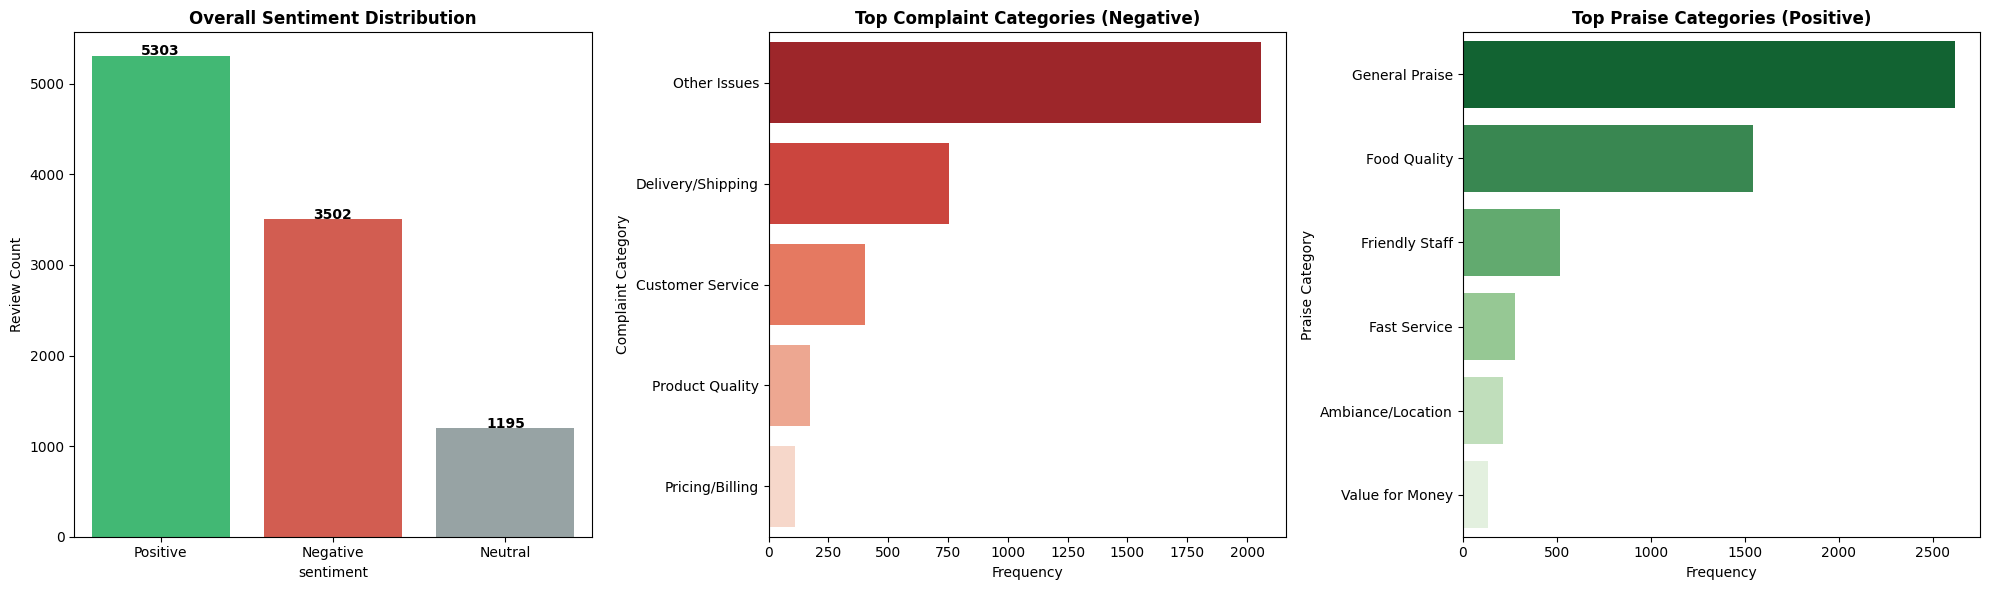

[transformers] Both `max_new_tokens` (=512) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

In [57]:
import gradio as gr

# Create the main Gradio app using Blocks layout
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 📊 Project A3: AI-Powered Customer Feedback Dashboard + Chatbot")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 📈 Sentiment & Theme Analytics")
            plot_component = gr.Plot(value=generate_dashboard_chart())
            refresh_btn = gr.Button("🔄 Refresh Charts")
            refresh_btn.click(fn=generate_dashboard_chart, inputs=[], outputs=plot_component)

            with gr.Row():
                with gr.Column():
                    gr.Markdown("### 🔴 Top Complaints")
                    gr.Dataframe(value=df_complaints_summary, interactive=False)
                with gr.Column():
                    gr.Markdown("### 🟢 Top Praise")
                    gr.Dataframe(value=df_praise_summary, interactive=False)

            gr.Markdown(f"**📝 Negative Summary:** *\"{system_negative_summary}\"*") # Display system-generated negative summary text
            gr.Markdown(f"**📝 Positive Summary:** *\"{system_positive_summary}\"*") # Display system-generated positive summary text

        with gr.Column(scale=1):
            gr.Markdown("### 💬 Ask About Your Data")
            chatbot_frame = gr.Chatbot(height=520)
            input_box = gr.Textbox(
                label="Ask anything about the dataset",
                placeholder="e.g. What do customers praise most? What are the top complaints?"
            )
            clear_btn = gr.ClearButton([input_box, chatbot_frame])
            input_box.submit(
                fn=chatbot_response,
                inputs=[input_box, chatbot_frame],
                outputs=[input_box, chatbot_frame]
            )

demo.launch(inline=False, share=True)